# 06 · Test e interpretación preliminar
**Proyecto Integrador ML2 — Segunda entrega · Predicción de la TRM**

**Objetivo (rúbrica 7.4).** Abrir el test —1.080 días, del 3 de marzo de 2022 al 26 de septiembre de 2026, que ningún paso anterior vio— **una sola vez**, con los modelos congelados en el notebook 05, y hacer la primera lectura del mejor modelo: **variables relevantes, estabilidad, errores e implicaciones**.

**Qué no se hace aquí:** elegir, ajustar o cambiar nada. Todo lo que se evalúa quedó fijado antes, y ningún resultado de este notebook vuelve atrás.

**Decisiones fijadas antes de abrir el test:**
- Se evalúan **las 7 configuraciones** (la validación y la prueba con Optuna mostraron que están empatadas) y el **método del artículo** en niveles, entrenado con todo el desarrollo.
- SHAP se aplica a **dos** modelos: el mejor congelado (**CatBoost solo TRM**) y el mejor **con macro** según la validación con la misma regla de menor RMSE medio (**CatBoost TRM + macro**, 20,768 pesos). El segundo es necesario porque el primero no usa variables macro y no podría contrastar la H5.

In [1]:
import sys, json, hashlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib, shap
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import r2_score
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

from src import config as cfg
from src.validacion import metricas
from src.graficos import estilo, guardar_figura, guardar_tabla, COLORES

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Verificar que se usa exactamente lo congelado
Antes de mirar el test se comprueba que la configuración no fue editada (MD5 de su contenido) y que los modelos cargados son los mismos que se congelaron: sus predicciones sobre el desarrollo deben tener la misma huella. Si algo falla, el notebook se detiene aquí.

In [2]:
congelada = json.loads(cfg.CONFIG_CONGELADA.read_text(encoding="utf-8"))
contenido = {k: v for k, v in congelada.items() if k != "md5_contenido"}
assert hashlib.md5(json.dumps(contenido, sort_keys=True, ensure_ascii=False).encode()).hexdigest() == congelada["md5_contenido"], \
    "config_congelada.json fue modificada"
assert hashlib.md5((cfg.DATA_PROC / "dataset.csv").read_bytes()).hexdigest() == congelada["md5_dataset"], "dataset.csv cambió"

modelos = joblib.load(cfg.MODELOS / "modelos_finales.joblib")
datos = pd.read_csv(cfg.DATA_PROC / "dataset.csv", parse_dates=["fecha"])
dev = datos[datos["muestra"] == "desarrollo"].reset_index(drop=True)
for nombre, m in modelos.items():
    vars_ = congelada["modelos"][nombre]["variables"]
    huella = hashlib.md5(np.round(m.predict(dev[vars_]), 12).tobytes()).hexdigest()
    assert huella == congelada["huella_predicciones_desarrollo"][nombre], f"{nombre}: no es el modelo congelado"
print(f"Configuración verificada (MD5 {congelada['md5_contenido']}); los 7 modelos coinciden con su huella.")
MEJOR = congelada["mejor_boosting"]
# Mejor con macro: misma regla que el mejor congelado (menor RMSE medio en validación), entre las versiones con macro.
val05 = pd.read_csv(cfg.TABLAS / "tab05_validacion.csv", index_col=0)
MEJOR_MACRO = val05.loc[[f"{m} · trm_macro" for m in cfg.MODELOS_BOOSTING], "rmse_media"].idxmin()
assert MEJOR_MACRO == "CatBoost · trm_macro"     # coincide con lo fijado antes de abrir el test
print(f"Mejor congelado: {MEJOR} | mejor con macro: {MEJOR_MACRO}")

Configuración verificada (MD5 0e4e09244ce880576a14400d9d91e75c); los 7 modelos coinciden con su huella.
Mejor congelado: CatBoost · solo_trm | mejor con macro: CatBoost · trm_macro


## 2. Se abre el test: Tabla 7

In [3]:
test = datos[datos["muestra"] == "test"].reset_index(drop=True)
print(f"Test: {len(test):,} días, {test['fecha'].min().date()} a {test['fecha'].max().date()}")

pred_test = pd.DataFrame({"fecha": test["fecha"], "trm": test["trm"], "trm_sig": test["trm_sig"], "y": test["y"]})
filas = []
for nombre, m in modelos.items():
    yhat = m.predict(test[congelada["modelos"][nombre]["variables"]])
    pred_test[nombre] = yhat
    filas.append({"modelo": nombre, **metricas(test["y"], yhat, test["trm"])})
t7 = pd.DataFrame(filas).set_index("modelo")
base = t7.loc["Línea base (lineal)"]
t7["delta_rmse_vs_base"] = t7["rmse_pesos"] - base["rmse_pesos"]
t7["delta_mae_vs_base"] = t7["mae_pesos"] - base["mae_pesos"]
t7["delta_r2_vs_base"] = t7["r2_retornos"] - base["r2_retornos"]

val = pd.read_csv(cfg.TABLAS / "tab05_validacion.csv", index_col=0)
t7["rmse_validacion"] = val["rmse_media"]
t7["r2_validacion"] = val["r2_media"]
guardar_tabla(t7, "tab07_test")
display(t7)

Test: 1,080 días, 2022-03-03 a 2026-09-26


,rmse_pesos,mae_pesos,r2_retornos,delta_rmse_vs_base,delta_mae_vs_base,delta_r2_vs_base,rmse_validacion,r2_validacion
modelo,,,,,,,,
Línea base (lineal),35.6281,27.1002,0.0368,0.0000,0.0000,0.0000,20.8334,0.0193
LightGBM · solo_trm,35.7530,27.2202,0.0322,0.1248,0.1200,-0.0046,20.7658,0.0175
LightGBM · trm_macro,35.8582,27.2604,0.0269,0.2301,0.1602,-0.0099,20.7742,0.0181
CatBoost · solo_trm,35.6409,27.0915,0.0370,0.0127,-0.0086,0.0002,20.7064,0.0249
CatBoost · trm_macro,36.3077,27.8132,0.0015,0.6796,0.7130,-0.0353,20.7679,0.0179
XGBoost · solo_trm,35.7899,27.2495,0.0290,0.1618,0.1493,-0.0078,20.8052,0.0160
XGBoost · trm_macro,36.3250,27.8206,-0.0010,0.6969,0.7204,-0.0378,20.9382,-0.0022


In [4]:
# El método del artículo (niveles, MinMax, parámetros por defecto), entrenado con TODO el desarrollo
art = datos.copy()
art["trm_l1"], art["trm_l5"], art["trm_l10"] = art["trm"], art["trm"].shift(4), art["trm"].shift(9)
XA = ["trm_l1", "trm_l5", "trm_l10"]
art_dev = art[(art["muestra"] == "desarrollo")].dropna(subset=XA)
art_test = art[art["muestra"] == "test"]
reproduccion = lambda m: TransformedTargetRegressor(regressor=Pipeline([("minmax", MinMaxScaler()), ("modelo", m)]),
                                                    transformer=MinMaxScaler())
filas = []
for nombre, m in {"LightGBM": LGBMRegressor(random_state=cfg.SEMILLA, verbose=-1),
                  "CatBoost": CatBoostRegressor(random_seed=cfg.SEMILLA, verbose=0, allow_writing_files=False),
                  "XGBoost": XGBRegressor(random_state=cfg.SEMILLA)}.items():
    p = reproduccion(m).fit(art_dev[XA], art_dev["trm_sig"]).predict(art_test[XA])
    real = art_test["trm_sig"].to_numpy()
    filas.append({"modelo (método del artículo)": nombre, "rmse_pesos": np.sqrt(np.mean((real - p) ** 2)),
                  "mae_pesos": np.mean(np.abs(real - p)), "r2_niveles": r2_score(real, p),
                  "prediccion_maxima": p.max(), "trm_maxima_test": real.max(),
                  "max_entrenamiento": art_dev["trm_sig"].max()})
t7b = pd.DataFrame(filas).set_index("modelo (método del artículo)")
guardar_tabla(t7b, "tab07b_articulo_en_test")
display(t7b)
print(f"Días del test con la TRM por encima del máximo del desarrollo: {(art_test['trm_sig'] > art_dev['trm_sig'].max()).mean():.1%}")

,rmse_pesos,mae_pesos,r2_niveles,prediccion_maxima,trm_maxima_test,max_entrenamiento
modelo (método del artículo),,,,,,
LightGBM,305.6870,184.6181,0.3869,"4,052.5979","5,061.2100","4,153.9100"
CatBoost,300.1317,179.6962,0.4090,"4,073.2097","5,061.2100","4,153.9100"
XGBoost,295.2161,176.7085,0.4282,"4,099.7329","5,061.2100","4,153.9100"


Días del test con la TRM por encima del máximo del desarrollo: 37.3%


**Lectura de la Tabla 7:**
- **En el test, la línea base es el mejor modelo** (RMSE 35,63 pesos, MAE 27,10, R² 0,037). CatBoost solo TRM, el mejor congelado, queda **empatado**: +0,013 pesos de RMSE y −0,009 de MAE, un centavo en cada dirección, y R² idéntico (0,037). Los otros boosting solo TRM quedan entre 0,12 y 0,16 pesos por detrás.
- **Las tres versiones con macro son las peores:** LightGBM +0,23, CatBoost +0,68 y XGBoost +0,70 pesos frente a la línea base. Las de CatBoost y XGBoost quedan con R² prácticamente nulo (0,002 y −0,001). En el test, **agregar las variables macro empeoró a los tres algoritmos**.
- **El error en pesos es mayor que en validación** (35,6 frente a 20,8), por dos razones que el EDA ya explicaba: la TRM está en niveles más altos (alrededor de 4.000 pesos), así que el mismo error relativo son más pesos, y el periodo es más volátil. Sin embargo, el **R² es mayor** (0,037 frente a 0,019): en el test, la memoria de un día de la TRM fue más aprovechable que en el promedio del desarrollo.
- **El método del artículo falla de nuevo, ahora en el test:** RMSE de 295 a 306 pesos, unas **8 veces** el de la línea base. Sus predicciones no pasan de 4.100 mientras la TRM llega a 5.061, y el 37 % de los días del test está por encima del máximo del desarrollo. La H6 se confirma fuera de la muestra.

## 3. Estabilidad: ¿el test confirma lo que dijo la validación?

In [5]:
orden = t7[["rmse_validacion", "rmse_pesos"]].rename(columns={"rmse_pesos": "rmse_test"})
orden["puesto_validacion"] = orden["rmse_validacion"].rank().astype(int)
orden["puesto_test"] = orden["rmse_test"].rank().astype(int)
rho = stats.spearmanr(orden["rmse_validacion"], orden["rmse_test"]).statistic
guardar_tabla(orden, "tab07c_estabilidad_validacion_test")
display(orden.sort_values("puesto_test"))
print(f"Correlación de rangos (Spearman) entre el orden en validación y en test: {rho:.2f}")
print(f"Rango de RMSE en test entre los 7 modelos: {t7['rmse_pesos'].max() - t7['rmse_pesos'].min():.3f} pesos")

,rmse_validacion,rmse_test,puesto_validacion,puesto_test
modelo,,,,
Línea base (lineal),20.8334,35.6281,6,1
CatBoost · solo_trm,20.7064,35.6409,1,2
LightGBM · solo_trm,20.7658,35.7530,2,3
XGBoost · solo_trm,20.8052,35.7899,5,4
LightGBM · trm_macro,20.7742,35.8582,4,5
CatBoost · trm_macro,20.7679,36.3077,3,6
XGBoost · trm_macro,20.9382,36.3250,7,7


Correlación de rangos (Spearman) entre el orden en validación y en test: 0.32
Rango de RMSE en test entre los 7 modelos: 0.697 pesos


**Lectura de estabilidad:**
- **El orden fino entre modelos no es estable** (Spearman de 0,32 entre validación y test). La línea base pasa del 6.º puesto en validación al 1.º en test. Es lo esperable cuando todos están empatados dentro de fracciones de peso: el orden lo decide el ruido del periodo.
- **Lo que sí es estable es el patrón grueso:** en test las tres versiones **solo TRM** superan a las tres versiones **con macro**, y en validación las macro tampoco aportaban de forma confiable. La conclusión no depende del periodo ni del método de búsqueda (sección 12 del notebook 05): **la señal está en la historia de la TRM y las macro no la mejoran**.
- **El mejor congelado**, CatBoost solo TRM, fue el más consistente: 1.º en validación y 2.º en test, a 0,013 pesos del 1.º. La elección fue razonable aunque el empate hace que no importe mucho cuál se elija.

## 4. Variables relevantes con SHAP (H5)
SHAP reparte cada predicción entre las variables: cuánto empujó cada una hacia arriba o hacia abajo respecto a la predicción promedio. Se calcula sobre los días del test. Se reporta la **importancia** (valor absoluto medio del aporte) y la **dirección** (correlación de Spearman entre el valor de la variable y su aporte: positiva si valores altos suben la predicción).

CatBoost · solo_trm


,importancia_media_abs,direccion_spearman,importancia_pct,signo_esperado_EDA
r_trm_l1,0.0012,0.9827,81.9541,+
r_trm_l10,0.0002,0.8016,12.8268,?
r_trm_l5,0.0001,-0.4676,5.2192,?


CatBoost · trm_macro


,importancia_media_abs,direccion_spearman,importancia_pct,signo_esperado_EDA
r_trm_l1,0.0011,0.9752,39.8296,+
dif_tasas,0.0009,0.2192,30.9097,−
r_dxy,0.0003,0.8045,11.0787,+
r_trm_l10,0.0002,0.8272,7.0754,?
r_brent,0.0002,-0.3311,6.2165,−
r_trm_l5,0.0001,-0.5323,4.8901,?


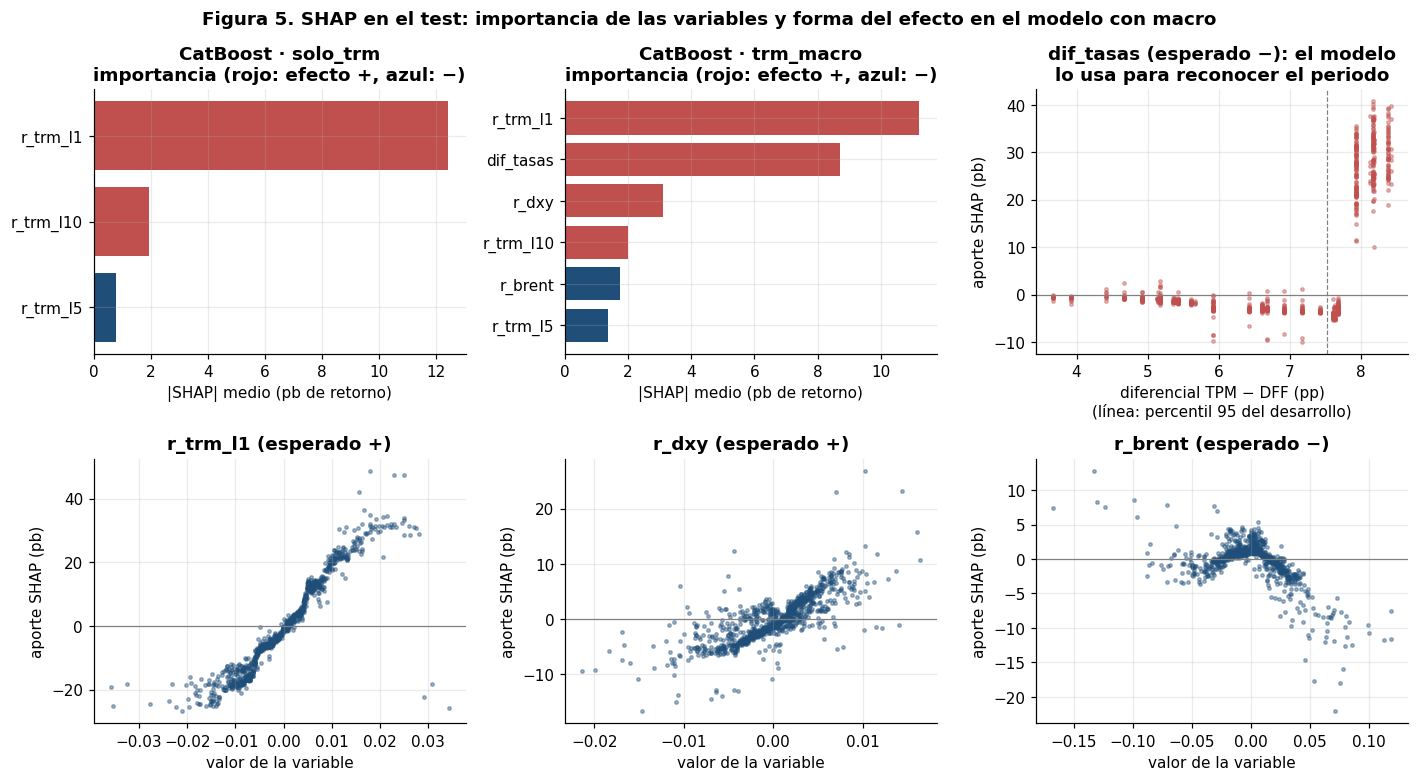

In [6]:
def shap_de(nombre):
    m = modelos[nombre].named_steps["modelo"]
    X = test[congelada["modelos"][nombre]["variables"]]
    valores = shap.TreeExplainer(m).shap_values(X)
    resumen = pd.DataFrame({
        "importancia_media_abs": np.abs(valores).mean(axis=0),
        "direccion_spearman": [stats.spearmanr(X[c], valores[:, i]).statistic for i, c in enumerate(X.columns)],
    }, index=X.columns)
    resumen["importancia_pct"] = 100 * resumen["importancia_media_abs"] / resumen["importancia_media_abs"].sum()
    return X, valores, resumen.sort_values("importancia_media_abs", ascending=False)

X_m, sv_m, res_m = shap_de(MEJOR)
X_mm, sv_mm, res_mm = shap_de(MEJOR_MACRO)
esperado = {"r_trm_l1": "+", "r_trm_l5": "?", "r_trm_l10": "?", "r_brent": "−", "r_dxy": "+", "dif_tasas": "−"}
for r in (res_m, res_mm):
    r["signo_esperado_EDA"] = r.index.map(esperado)
guardar_tabla(res_m, "tab08_shap_mejor"); guardar_tabla(res_mm, "tab08b_shap_mejor_macro")
print(MEJOR); display(res_m)
print(MEJOR_MACRO); display(res_mm)

fig, ejes = plt.subplots(2, 3, figsize=(13, 7.2))
for eje, (tit, r) in zip(ejes[0, :2], [(MEJOR, res_m), (MEJOR_MACRO, res_mm)]):
    colores = [COLORES[1] if d > 0 else COLORES[0] for d in r["direccion_spearman"]]
    eje.barh(r.index[::-1], 1e4 * r["importancia_media_abs"][::-1], color=colores[::-1])
    eje.set(title=f"{tit}\nimportancia (rojo: efecto +, azul: −)", xlabel="|SHAP| medio (pb de retorno)")
i_d = list(X_mm.columns).index("dif_tasas")
ejes[0, 2].scatter(X_mm["dif_tasas"], 1e4 * sv_mm[:, i_d], s=5, alpha=0.4, color=COLORES[1])
ejes[0, 2].axvline(np.percentile(dev["dif_tasas"], 95), color="grey", ls="--", lw=0.8)
ejes[0, 2].axhline(0, color="grey", lw=0.8)
ejes[0, 2].set(title="dif_tasas (esperado −): el modelo\nlo usa para reconocer el periodo", xlabel="diferencial TPM − DFF (pp)\n(línea: percentil 95 del desarrollo)",
               ylabel="aporte SHAP (pb)")
for eje, v in zip(ejes[1], ["r_trm_l1", "r_dxy", "r_brent"]):
    i = list(X_mm.columns).index(v)
    eje.scatter(X_mm[v], 1e4 * sv_mm[:, i], s=5, alpha=0.4, color=COLORES[0])
    eje.axhline(0, color="grey", lw=0.8)
    eje.set(title=f"{v} (esperado {esperado[v]})", xlabel="valor de la variable", ylabel="aporte SHAP (pb)")
fig.suptitle("Figura 5. SHAP en el test: importancia de las variables y forma del efecto en el modelo con macro",
             fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "fig05_shap"); plt.show()

In [7]:
# Diagnóstico: ¿por qué el modelo con macro le da tanto peso al diferencial?
p95_dev = np.percentile(dev["dif_tasas"], 95)
sesgo = pd.DataFrame({
    "prediccion_media_pb": {n: 1e4 * pred_test[n].mean() for n in modelos},
    "desv_est_prediccion_pb": {n: 1e4 * pred_test[n].std() for n in modelos},
})
sesgo.loc["Retorno real (test)"] = [1e4 * test["y"].mean(), 1e4 * test["y"].std()]
diag = pd.Series({
    "dif_tasas_mediana_desarrollo": dev["dif_tasas"].median(), "dif_tasas_mediana_test": test["dif_tasas"].median(),
    "pct_dias_test_en_el_5pct_superior_del_desarrollo": 100 * (test["dif_tasas"] > p95_dev).mean(),
}, name="valor")
guardar_tabla(sesgo, "tab08c_sesgo_predicciones"); guardar_tabla(diag.to_frame(), "tab08d_diferencial_test")
display(diag.to_frame()); display(sesgo)

,valor
dif_tasas_mediana_desarrollo,3.7000
dif_tasas_mediana_test,6.6100
pct_dias_test_en_el_5pct_superior_del_desarrollo,35.1852


,prediccion_media_pb,desv_est_prediccion_pb
Línea base (lineal),0.3293,14.8572
LightGBM · solo_trm,1.0103,13.3687
LightGBM · trm_macro,0.5459,17.5638
CatBoost · solo_trm,0.4801,15.5868
CatBoost · trm_macro,5.5874,22.2123
XGBoost · solo_trm,0.2968,15.6049
XGBoost · trm_macro,6.1575,20.2216
Retorno real (test),-1.3202,87.8198


**Lectura de SHAP (H5) y diagnóstico:**
- **CatBoost solo TRM:** `r_trm_l1` concentra el **82 %** de la importancia, con efecto positivo casi perfecto (dirección +0,98). Es el efecto de promedio que el EDA identificó (E4). Los rezagos 5 y 10 aportan poco (5 % y 13 %).
- **CatBoost TRM + macro:**
  - Los signos de las macro **coinciden con la teoría y con el EDA**: `r_dxy` positivo (+0,80) y `r_brent` negativo (−0,33).
  - Su peso es pequeño: el DXY 11 % y el Brent 6 %.
  - La segunda variable más importante es **`dif_tasas`, con el 31 %**, pese a que el EDA mostró que no se relaciona con el retorno diario (E5: correlación de 0,008).
- **El diagnóstico explica el mal desempeño de las macro en el test.**
  - **Qué aprendió el modelo:** en el desarrollo, los valores altos del diferencial coinciden con periodos concretos de devaluación. El modelo usa el diferencial para **reconocer el periodo**, no para predecir la dirección, justo lo que advirtieron E7 y E9.
  - **Qué pasa en el test:** el diferencial se mantiene alto, con una mediana de 6,6 frente a 3,7 en desarrollo, y el 35 % de los días en el 5 % superior del desarrollo.
  - **Resultado:** el modelo predice una **devaluación sistemática**, de **+5,6 pb diarios** en promedio, cuando la TRM real bajó en promedio 1,3 pb. Sus predicciones son además más extremas: desviación de 22 pb frente a 15 de la línea base.

  - **La Figura 5, arriba a la derecha, lo muestra directamente:** el aporte del diferencial es plano, cercano a cero, hasta unos 7,8 puntos, y ahí salta de golpe a **+20 a +40 pb** por predicción. Es un escalón, no una relación económica: el modelo aprendió "diferencial muy alto = periodo de devaluación".

  **Es sobreajuste a un régimen, no información.**
- **Veredicto H5:** se confirma para `r_trm_l1`, `r_dxy` y `r_brent`, con signos y orden de importancia correctos. **No se confirma para `dif_tasas`**, y esa falla es la que explica el resultado. Que el EDA lo anticipara antes de entrenar le da solidez a la conclusión.

## 5. Errores en el tiempo: Figura 6
El test cubre tres periodos distintos: la **subida al máximo** (hasta el 3 de noviembre de 2022, TRM de 5.061), la **corrección** (noviembre de 2022 a 2025) y el **choque petrolero de 2026** (guerra con Irán; el Brent pasa de 62 a 138 USD). Se mide el error de cada modelo por periodo y el error móvil de 60 días.

periodo,Subida al máximo,Corrección,Choque petrolero 2026
dias,164.0000,743.0000,173.0000
volatilidad_anual_pct,17.7468,13.1328,12.9447
rmse · Línea base (lineal),46.0020,34.5933,27.9050
r2 · Línea base (lineal),0.0469,0.0272,0.0086
rmse · CatBoost · solo_trm,45.7820,34.6819,27.8774
r2 · CatBoost · solo_trm,0.0554,0.0232,0.0128
rmse · CatBoost · trm_macro,45.5040,35.6714,28.3146
r2 · CatBoost · trm_macro,0.0658,-0.0300,-0.0278
rmse · LightGBM · trm_macro,46.1855,34.8616,28.0233
r2 · LightGBM · trm_macro,0.0417,0.0141,0.0046


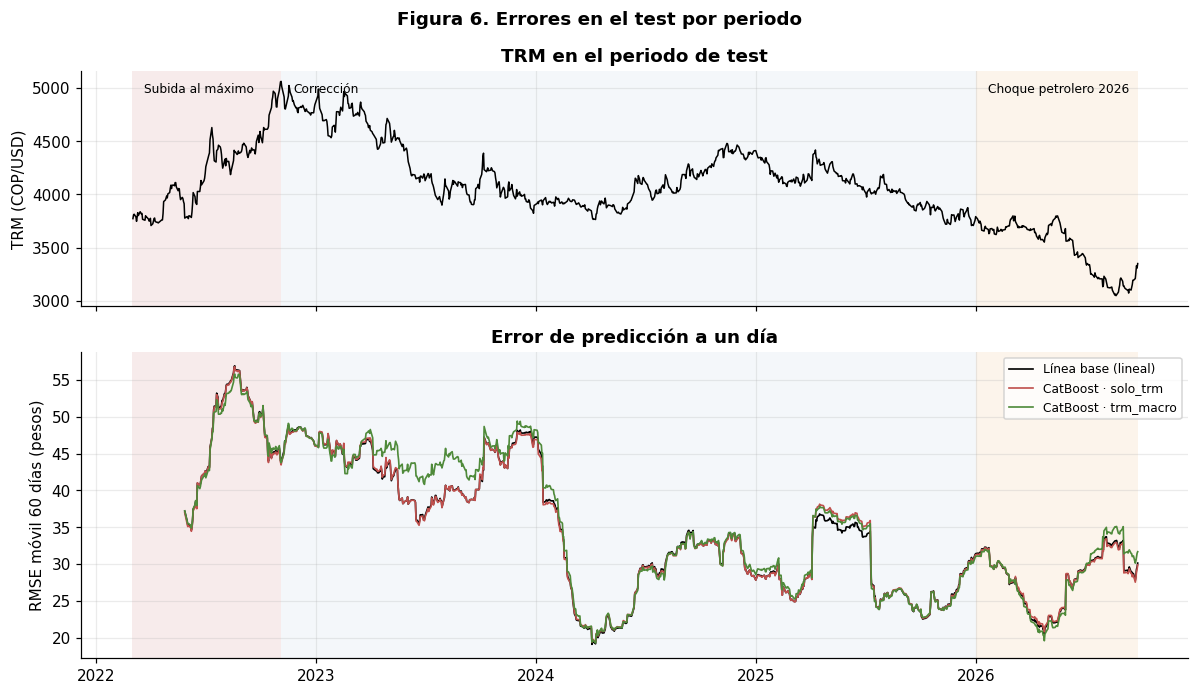

In [8]:
periodos = [("Subida al máximo", "2022-03-01", "2022-11-03"), ("Corrección", "2022-11-04", "2025-12-31"),
            ("Choque petrolero 2026", "2026-01-01", "2026-12-31")]
comparar = ["Línea base (lineal)", MEJOR, MEJOR_MACRO, "LightGBM · trm_macro", "XGBoost · trm_macro"]
filas = []
for nombre_p, a, b in periodos:
    g = pred_test[(pred_test["fecha"] >= a) & (pred_test["fecha"] <= b)]
    fila = {"periodo": nombre_p, "dias": len(g), "volatilidad_anual_pct": 100 * g["y"].std() * np.sqrt(252)}
    for n in comparar:
        met = metricas(g["y"], g[n], g["trm"])
        fila[f"rmse · {n}"], fila[f"r2 · {n}"] = met["rmse_pesos"], met["r2_retornos"]
    filas.append(fila)
t9 = pd.DataFrame(filas).set_index("periodo")
guardar_tabla(t9, "tab09_error_por_periodo")
display(t9.T)

err = lambda n: pred_test["trm_sig"] - pred_test["trm"] * np.exp(pred_test[n])
fig, ejes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
ejes[0].plot(pred_test["fecha"], pred_test["trm_sig"], color="black", lw=1)
ejes[0].set(ylabel="TRM (COP/USD)", title="TRM en el periodo de test")
for n, c in zip(["Línea base (lineal)", MEJOR, MEJOR_MACRO], ["black", COLORES[1], COLORES[2]]):
    ejes[1].plot(pred_test["fecha"], np.sqrt((err(n) ** 2).rolling(60).mean()), color=c, lw=1.1, label=n)
for (nombre_p, a, b), c in zip(periodos, ["#f2dede", "#eef3f8", "#fbeede"]):
    for eje in ejes:
        eje.axvspan(pd.Timestamp(a), min(pd.Timestamp(b), pred_test["fecha"].max()), color=c, alpha=0.6, lw=0)
    ejes[0].text(pd.Timestamp(a) + pd.Timedelta(days=20), pred_test["trm_sig"].max() * 0.98, nombre_p, fontsize=8)
ejes[1].set(ylabel="RMSE móvil 60 días (pesos)", title="Error de predicción a un día")
ejes[1].legend(fontsize=8)
fig.suptitle("Figura 6. Errores en el test por periodo", fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "fig06_errores_test"); plt.show()
pred_test.to_csv(cfg.DATA_PROC / "predicciones_test.csv", index=False)

**Lectura por periodo (Tabla 9 y Figura 6):**
- **Subida al máximo** (marzo a noviembre de 2022; volatilidad del 17,7 %): es el único periodo donde el modelo con macro le gana a la línea base (45,50 frente a 46,00 pesos; R² 0,066 frente a 0,047). En un periodo de dólar global fuerte, el DXY aporta, como en el corte 5 de la validación (COVID).
- **Corrección** (noviembre de 2022 a 2025; 743 días): las macro empeoran el modelo (35,67 frente a 34,59 pesos; R² −0,030). Es el periodo largo en que el sesgo por el diferencial alto hace más daño, porque la TRM bajó mientras el modelo esperaba subidas.
- **Choque petrolero de 2026:** las macro **tampoco ayudan** (28,31 frente a 27,91 pesos). Esto matiza lo que se esperaba del EDA (E10): en 2026 el Brent subió por un choque de oferta geopolítico mientras la TRM bajaba, pero el efecto del diferencial alto domina y el Brent pesa poco en el modelo (6 %). Un choque petrolero no garantiza que las macro aporten.
- **El error más alto está en el periodo más volátil,** la subida al máximo (46 pesos), y el más bajo en 2026 (28): la H4 se confirma también en el test.

## 6. Cierre de las hipótesis del EDA

| | Hipótesis (escrita antes de entrenar) | Validación (nb 05) | Test (este notebook) | Veredicto |
|---|---|---|---|---|
| **H1** | La línea base logra un R² pequeño y positivo, cercano a 0,03 | 0,019 (4/5 cortes positivos) | **0,037** | **Confirmada** |
| **H2** | Los boosting no superan de forma apreciable a la línea base | Mejor +0,0056 de R², −0,13 pesos, MAE igual | Mejor boosting **empata** (+0,013 pesos) y los demás pierden | **Confirmada** |
| **H3** | Las macro aportan poco y de forma inestable | No aportan de forma confiable en ningún algoritmo | **Empeoran a los tres** (+0,23 a +0,70 pesos) | **Confirmada**, con más fuerza: fuera de muestra las macro restan |
| **H4** | El error es mayor en periodos turbulentos | Correlación volatilidad–RMSE 0,61 | Subida al máximo 46 pesos frente a 28 en 2026 | **Confirmada** |
| **H5** | SHAP: `r_trm_l1` dominante, DXY +, Brent −, el resto mínimo | — | Correcta para `r_trm_l1`, DXY y Brent; **falla en `dif_tasas` (31 %)** | **Confirmada en parte**; la falla explica H3 |
| **H6** | El método del artículo en niveles falla fuera del rango | RMSE 317–333 pesos (nb 04) | RMSE 295–306 pesos; predicciones ≤ 4.100 frente a 5.061 | **Confirmada** |

Cinco de las seis hipótesis se confirman y la sexta en parte. Lo que no se cumplió (el diferencial) también estaba advertido por el EDA (E7, E9) como riesgo de sobreajuste. **El EDA anticipó los resultados antes de entrenar los modelos**, y por eso el resultado negativo tiene fundamento.

## 7. Implicaciones y respuesta preliminar a la pregunta de investigación

**Pregunta (Entrega 1):** ¿la incorporación de variables macroeconómicas locales (petróleo, diferencial de tasas Banrep–Fed, fortaleza del dólar) mejora la predicción del precio diario de la TRM frente a un modelo que solo usa su comportamiento pasado, y cuál de los tres algoritmos de gradient boosting aprovecha mejor esa información?

**Respuesta preliminar:** **no la mejora.** En validación, las macro no aportan de forma confiable en ninguno de los tres algoritmos; en el test, los **empeoran a los tres**. La poca señal predecible de la TRM diaria está en su **movimiento del día anterior** (efecto de promedio). Una regresión lineal la aprovecha tan bien como el mejor boosting: en el test empatan dentro de un centavo. Sobre qué algoritmo aprovecha mejor las macro, **LightGBM es el que menos se perjudica** (+0,23 pesos frente a +0,68 y +0,70), pero ninguno las aprovecha. El mecanismo está identificado: el diferencial de tasas lleva a sobreajustar el régimen, y el Brent y el DXY tienen signos correctos pero una relación diaria débil e inestable.

**Implicaciones prácticas:**
- **Para un importador o tesorero:** el error típico a un día es de unos **27 pesos por dólar** (MAE en el test), y ningún modelo lo reduce de forma material frente a una regresión simple sobre la TRM de los días anteriores. Para decisiones diarias, un modelo complejo con variables macro **no justifica su costo**. Lo útil es la señal de corto plazo: si la TRM subió hoy, mañana tiende a subir un poco.
- **Para el Banco de la República o un analista:** que las macro no predigan el día siguiente **no significa que no importen**. El diferencial de tasas y el petróleo actúan en horizontes de semanas o meses (carry, términos de intercambio), no en el siguiente día hábil. La conclusión correcta es "estas variables no mejoran la predicción a un día", no "no afectan la TRM".
- **Metodológicas:** el método del artículo, aplicado tal cual, sobreestimaría su capacidad por el R² en niveles y fallaría fuera del rango histórico. Adaptarlo a retornos es imprescindible para que la comparación tenga sentido.

**Sobre el hallazgo del diferencial de tasas: no es fuga de información.** La fuga ocurre cuando un modelo usa información que no tendría al predecir, e infla los resultados; aquí no la hay (prueba de perturbación, notebook 02, y auditorías, notebook 05). Lo que ocurrió es un **cambio de distribución**: el test visita valores del diferencial que en el desarrollo solo aparecían en periodos de devaluación, y una relación aprendida del pasado dejó de valer. Por eso empeora el resultado en lugar de inflarlo. Corregirlo ahora, mirando el test, violaría el protocolo. Queda como **proyección para la Entrega final**: probar el diferencial expresado como cambio y no como nivel, con datos posteriores al 29 de septiembre de 2026 que ningún modelo ha visto.

**Limitaciones:**
- Las diferencias entre modelos son de fracciones de peso. Sin una prueba formal (Diebold-Mariano, pendiente), "empatan" se afirma con base en su tamaño frente a la variación entre periodos.
- El test cubre un solo periodo de 4,5 años con un diferencial de tasas atípicamente alto.
- Solo se usaron las variables prometidas en la Entrega 1. Variables de riesgo global o de monedas de la región podrían comportarse distinto a un día.